# TP 2 

In [1]:
import os
import yake

from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences



# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tvh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Choix de l'année 

In [2]:
year = 1888
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))


## Extractions des mots clés de 1888

In [3]:
# Récupérer le texte du fichier
this_file = '1888.txt'
text = open(os.path.join(temp_path, this_file), 'r', encoding='utf-8').read()
text[:500]
keywords = kw_extractor.extract_keywords(text)
keywords

[('rue', np.float64(8.16807566272382e-06)),
 ('louer belle maison', np.float64(1.573712591103054e-05)),
 ('Bruxelles', np.float64(2.0806293901501796e-05)),
 ('rue Neuve BRUXELLES', np.float64(3.209338930618603e-05)),
 ('GRAND CONCOURS BRUXELLES', np.float64(3.542914903752088e-05)),
 ('Maison', np.float64(3.7176403508749395e-05)),
 ('Agence Rossel', np.float64(4.434276767776142e-05)),
 ('louer jolie maison', np.float64(5.100321259501684e-05)),
 ('maison rue Van', np.float64(5.2198602351094226e-05)),
 ('louer grande maison', np.float64(5.4496889723699014e-05)),
 ('maison rue', np.float64(5.73035190793882e-05)),
 ('rue Royale', np.float64(5.76718881293347e-05)),
 ('rue Van', np.float64(7.422362227570287e-05)),
 ('belle maison', np.float64(7.527359889806945e-05)),
 ('louer maison', np.float64(7.765482567527483e-05)),
 ('belle maison rue', np.float64(7.92490155795695e-05)),
 ('place', np.float64(8.246717579759794e-05)),
 ('louer', np.float64(9.529170974497326e-05)),
 ('Grand concours', np.f

## Stop words et nuage de mots

In [4]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)

In [5]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [6]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1888_clean.txt!'

In [7]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'AUTEURS RARE AUDACE MESSIEURS DISANT INSPECTEURS POLICE PRÉSENTÈRENT CHEZ EXHIBANT MANDAT AMENER ESMÔ PÀÏ PROCUREUR RÉPUBLIQUE ACCUSÉO DÉTOURNEMENT VALEURS ÉAANT MARI MÀIGR PROTESTATIONS DEW LIE VOULURENT RIEN ENTENDRE CONNAISSANT DISAIENT LEUX DEVOIR TOUTEFOIS FINI RENT CONSENTIR ALLER DEMANDER PROCU RÊUR RÉPUBLIQUE LAISSER LIBERTÉ BOUS CAUTION DEMI HEURE ABSENCE REVINRENT AUTORISATION LAISSER LIBERTÉ CAUTION VERSER IMMÉDIATEMENT ENTRO LEURS MAINS GETTÈ DERNIÈRE DÉFIANCE EMPRESSA EOMPTOR SOMME '

In [8]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 2741), ('BRUXELLES', 947), ('MAISON', 931), ('PLACE', 760), ('LOUER', 729), ('ANS', 614), ('HEURES', 609), ('PRIX', 572), ('TRÈS', 507), ('GRAND', 498)]


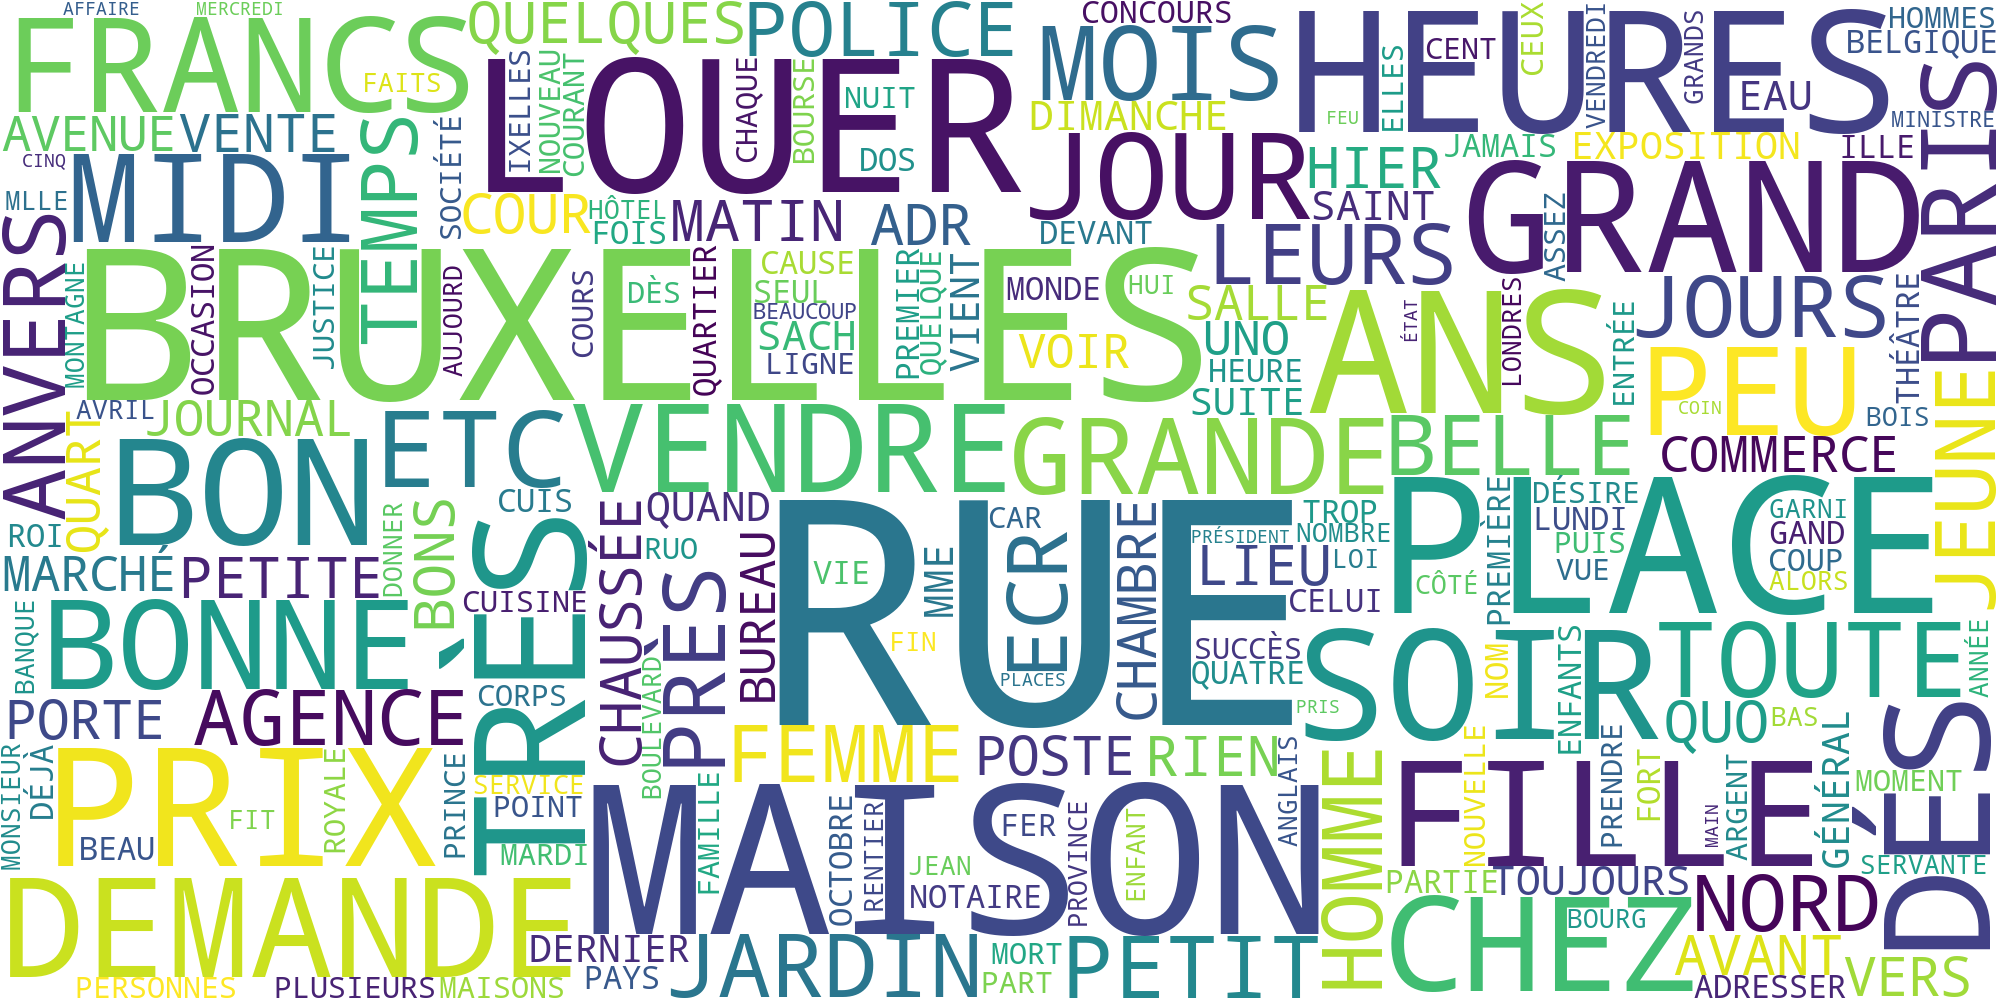

In [9]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Entités nommées

In [12]:
nlp = spacy.load('fr_core_news_md')

# Charger le texte
n=1000000
text = open("../../data/tmp/1888_clean.txt", encoding='utf-8').read()[:n]

In [13]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: total: 34.3 s
Wall time: 34.9 s


In [14]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1

In [15]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

WILSON apparait 5 fois dans le corpus
LOUÉE apparait 5 fois dans le corpus
ORGANE apparait 3 fois dans le corpus
VANDERLINDEN apparait 3 fois dans le corpus
GRABAT apparait 3 fois dans le corpus
TERRIBLES apparait 2 fois dans le corpus
SOUFFRIR apparait 2 fois dans le corpus
MORDU apparait 2 fois dans le corpus
BONNO apparait 2 fois dans le corpus
VIEUX BROCANTEUR apparait 2 fois dans le corpus
SERRES apparait 2 fois dans le corpus
HECTARES apparait 2 fois dans le corpus
MOUCHOIRS apparait 2 fois dans le corpus
LIQUEURS apparait 2 fois dans le corpus
LOUIS GRAND apparait 2 fois dans le corpus
MARÉCHAL COUR apparait 1 fois dans le corpus
CANNÉS PERSONNI apparait 1 fois dans le corpus
PLACE RESPECTIVE apparait 1 fois dans le corpus
TOURNAI PTIM apparait 1 fois dans le corpus
TISZA COTIRS apparait 1 fois dans le corpus
AMBASSADEUR RUSSIE apparait 1 fois dans le corpus
VIENNOIS STANDARD apparait 1 fois dans le corpus
ALI BABA VAUDEVILLE apparait 1 fois dans le corpus
QMI SQIT apparait 1 fo

## Analyse de sentiment